In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

In [2]:
TEXT_COL = "summaries"
LABEL_COL = "terms"  # Pair using label names, not multi-hot vectors

SAMPLE_SIZE = 200
NUM_QUANTILES = 100
RANDOM_SEED = 20261031
NUM_REPETITIONS = 10
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]
# 明确使用第一块 CUDA GPU；不可用时停止，不静默退回 CPU。
DEVICE = "cuda:0"

from pathlib import Path
NOTEBOOK_DIR = Path.cwd()
if (NOTEBOOK_DIR / "arXiv" / "arxiv_data.csv").is_file():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "arXiv"
if not (NOTEBOOK_DIR / "arxiv_data.csv").is_file():
    raise FileNotFoundError("Open in GR or arXiv; arxiv_data.csv is required.")
ROOT = NOTEBOOK_DIR.parent

from datetime import datetime
import json
import pickle
if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable: select the RTX 5080 .venv Python kernel.")
print("GPU:", torch.cuda.get_device_name(0))
torch.backends.cuda.matmul.allow_tf32 = False
OUTPUT_DIR = NOTEBOOK_DIR / "results" / ("uncertainty10_gpu_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Results directory:", OUTPUT_DIR.resolve())


GPU: NVIDIA GeForce RTX 5080
Results directory: /home/amyliu/Desktop/GR/arXiv/results/uncertainty10_gpu_20261025_185210


In [3]:
df = pd.read_csv(NOTEBOOK_DIR / "arxiv_data.csv")
df.head(10)

,titles,summaries,terms
0,Survey on Semantic Stereo Matching / Semantic ...,Stereo matching is one of the widely used tech...,"['cs.CV', 'cs.LG']"
1,FUTURE-AI: Guiding Principles and Consensus Re...,The recent advancements in artificial intellig...,"['cs.CV', 'cs.AI', 'cs.LG']"
2,Enforcing Mutual Consistency of Hard Regions f...,"In this paper, we proposed a novel mutual cons...","['cs.CV', 'cs.AI']"
3,Parameter Decoupling Strategy for Semi-supervi...,Consistency training has proven to be an advan...,['cs.CV']
4,Background-Foreground Segmentation for Interio...,"To ensure safety in automated driving, the cor...","['cs.CV', 'cs.LG']"
5,EdgeFlow: Achieving Practical Interactive Segm...,High-quality training data play a key role in ...,"['cs.CV', 'cs.HC']"
6,Efficient Hybrid Transformer: Learning Global-...,Semantic segmentation of fine-resolution urban...,['cs.CV']
7,Towards to Robust and Generalized Medical Imag...,"To mitigate the radiologist's workload, comput...","['cs.CV', 'cs.AI']"
8,Semi-supervised Meta-learning with Disentangle...,Generalising deep models to new data from new ...,['cs.CV']
9,Semi-supervised Contrastive Learning for Label...,The success of deep learning methods in medica...,['cs.CV']


In [4]:
print(df.shape)
print(type(df["terms"].iloc[0]))
import ast
from collections import Counter
from sklearn.preprocessing import MultiLabelBinarizer

# 在原始 terms 上统计文档频次；每篇文章中同一标签只计一次。
parsed_labels = df["terms"].map(
    lambda value: ast.literal_eval(value) if isinstance(value, str) else value
)
label_counts = Counter(
    label for labels in parsed_labels for label in set(labels)
)
top_9_labels = [label for label, _ in label_counts.most_common(9)]
top_9_set = set(top_9_labels)
original_size = len(df)

# 先直接修改 df：删除非前九类标签，再删除不含前九类的文章。
# terms 现在存储实际列表；保留的文章仍可含多个标签，不设置 Other 类。
df["terms"] = parsed_labels.map(
    lambda labels: list(dict.fromkeys(
        label for label in labels if label in top_9_set
    ))
)
df = df.loc[df["terms"].str.len().gt(0)].copy().reset_index(drop=True)

# 显式固定九个输出位置，顺序与 top_9_labels 一致。
mlb = MultiLabelBinarizer(classes=top_9_labels)
label_matrix = mlb.fit_transform(df["terms"])
df["labels"] = label_matrix.tolist()

print("保留的九大类别：", top_9_labels)
print("原始文章数量：", original_size)
print("保留文章数量：", len(df))
print("删除文章数量：", original_size - len(df))
print("Multi-hot 矩阵形状：", label_matrix.shape)
print("向量位置对应的标签顺序：", mlb.classes_.tolist())
display(df[["terms", "labels"]].head(10))
print(df.shape)
print(label_matrix.shape)

(51774, 3)
<class 'str'>
保留的九大类别： ['cs.CV', 'cs.LG', 'stat.ML', 'cs.AI', 'eess.IV', 'cs.RO', 'cs.CL', 'cs.NE', 'cs.CR']
原始文章数量： 51774
保留文章数量： 51774
删除文章数量： 0
Multi-hot 矩阵形状： (51774, 9)
向量位置对应的标签顺序： ['cs.CV', 'cs.LG', 'stat.ML', 'cs.AI', 'eess.IV', 'cs.RO', 'cs.CL', 'cs.NE', 'cs.CR']


,terms,labels
0,"[cs.CV, cs.LG]","[1, 1, 0, 0, 0, 0, 0, 0, 0]"
1,"[cs.CV, cs.AI, cs.LG]","[1, 1, 0, 1, 0, 0, 0, 0, 0]"
2,"[cs.CV, cs.AI]","[1, 0, 0, 1, 0, 0, 0, 0, 0]"
3,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"
4,"[cs.CV, cs.LG]","[1, 1, 0, 0, 0, 0, 0, 0, 0]"
5,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"
6,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"
7,"[cs.CV, cs.AI]","[1, 0, 0, 1, 0, 0, 0, 0, 0]"
8,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"
9,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]"


(51774, 4)
(51774, 9)


In [5]:
def sample_from_length_groups(
    df,
    text_col,
    sample_size=200,
    num_quantiles=100,
    random_seed=42,
    length_fn=None,
    length_col="length",
    group_col="quantiles",
    return_grouped=False,
):
    """按文本长度分位组无放回抽样，不修改输入或依赖标签格式。

    默认长度是空白分隔词数。length_fn 可传入接收单篇文本并返回长度的函数，
    例如 len（字符数），或 lambda text: len(tokenizer.encode(text))。
    返回原有列和原始文本，并新增 length_col 和 group_col（Q1、Q2……）。
    缺失、空白文本不参与抽样。return_grouped=True 时返回
    (sampled_df, grouped_df)，后者包含全部有效文章的长度和分组，供后续复用。
    """
    if len({text_col, length_col, group_col}) != 3:
        raise ValueError("Text, length and group column names must be different")
    if length_col in df.columns or group_col in df.columns:
        raise ValueError("Length/group output columns already exist; choose unused output names")
    if text_col not in df.columns:
        raise ValueError(f"Missing text column: {text_col}")
    for name, value in [("sample_size", sample_size), ("num_quantiles", num_quantiles)]:
        if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError(f"{name} must be a positive integer")

    text = df[text_col].fillna("").astype(str).str.strip()
    pool = df.loc[text.ne("")].copy().reset_index(drop=True)
    text = text.loc[text.ne("")].reset_index(drop=True)
    if sample_size > len(pool):
        raise ValueError(f"Requested {sample_size} rows, but only {len(pool)} valid texts")

    lengths = text.str.split().str.len() if length_fn is None else text.map(length_fn)
    lengths = pd.to_numeric(lengths, errors="raise")
    if not np.isfinite(lengths.to_numpy(dtype=float)).all() or lengths.lt(0).any():
        raise ValueError("Text lengths must be finite, non-negative numbers")

    q = min(num_quantiles, sample_size, lengths.nunique())
    # 相同长度不拆组；所有文本长度相同时使用一个组。
    groups = (
        pd.Series(np.zeros(len(pool), dtype=int))
        if q <= 1 else pd.qcut(lengths, q=q, labels=False, duplicates="drop")
    )
    # 分组基于完整有效数据，而不是抽样后的数据。
    pool[length_col] = lengths.to_numpy()
    pool[group_col] = pd.Categorical(
        groups.map(lambda group: f"Q{int(group) + 1}"),
        categories=[f"Q{int(group) + 1}" for group in sorted(groups.unique())],
        ordered=True,
    )
    group_indices = list(groups.groupby(groups, sort=True).groups.values())
    rng = np.random.default_rng(random_seed)
    base_n = sample_size // len(group_indices)
    selected = []
    for indices in group_indices:
        selected.extend(rng.choice(
            np.asarray(indices), size=min(base_n, len(indices)), replace=False
        ).tolist())

    # 分位组不足或较小时，从未选中的行补足目标数量。
    remaining_n = sample_size - len(selected)
    if remaining_n:
        remaining_indices = np.setdiff1d(np.arange(len(pool)), selected)
        selected.extend(rng.choice(remaining_indices, size=remaining_n, replace=False).tolist())
    rng.shuffle(selected)
    sampled_df = pool.iloc[selected].copy().reset_index(drop=True)
    sampled_lengths = lengths.iloc[selected]
    print("Valid texts:", len(pool))
    print("Length groups:", len(group_indices))
    print("Actual sample size:", len(sampled_df))
    print("Length measure:", "whitespace word count" if length_fn is None else "custom length_fn")
    print("Sample length min / mean / max:",
          sampled_lengths.min(), sampled_lengths.mean(), sampled_lengths.max())
    return (sampled_df, pool) if return_grouped else sampled_df


In [6]:
sampled_df, grouped_df = sample_from_length_groups(
    df=df,
    text_col=TEXT_COL,
    sample_size=SAMPLE_SIZE,
    num_quantiles=NUM_QUANTILES,
    random_seed=RANDOM_SEED,
    length_col="length",
    group_col="quantiles",
    return_grouped=True,
)
display(sampled_df.head())

# grouped_df：全部有效文章；sampled_df：抽样文章，两者均保留长度和分组。
display(grouped_df[[TEXT_COL, "length", "quantiles"]].head())


Valid texts: 51774
Length groups: 100
Actual sample size: 200
Length measure: whitespace word count
Sample length min / mean / max: 71 173.54 293


,titles,summaries,terms,labels,length,quantiles
0,Spatiotemporal Attention Networks for Wind Pow...,Wind power is one of the most important renewa...,[cs.LG],"[0, 1, 0, 0, 0, 0, 0, 0, 0]",115,Q10
1,CSL-YOLO: A New Lightweight Object Detection S...,The development of lightweight object detector...,[cs.CV],"[1, 0, 0, 0, 0, 0, 0, 0, 0]",112,Q9
2,Tracking by Animation: Unsupervised Learning o...,Online Multi-Object Tracking (MOT) from videos...,"[cs.CV, cs.LG, stat.ML]","[1, 1, 1, 0, 0, 0, 0, 0, 0]",172,Q51
3,Improving Text to Image Generation using Mode-...,Generative Adversarial Networks (GANs) have lo...,"[cs.CV, eess.IV]","[1, 0, 0, 0, 1, 0, 0, 0, 0]",117,Q11
4,A Robust Pose Transformational GAN for Pose Gu...,Generating photorealistic images of human subj...,"[cs.CV, cs.LG, eess.IV]","[1, 1, 0, 0, 1, 0, 0, 0, 0]",151,Q33


,summaries,length,quantiles
0,Stereo matching is one of the widely used tech...,132,Q19
1,The recent advancements in artificial intellig...,206,Q78
2,"In this paper, we proposed a novel mutual cons...",227,Q88
3,Consistency training has proven to be an advan...,198,Q72
4,"To ensure safety in automated driving, the cor...",274,Q99


In [7]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    if not torch.cuda.is_available():
        raise RuntimeError("CUDA unavailable: select the CUDA-enabled Python environment")
    device = torch.device(DEVICE)
    print("GPU:", torch.cuda.get_device_name(device), flush=True)

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [8]:
def asymmetry_eta(x, bandwidth=None):
    """Original leave-one-out eta estimator, evaluated in float64 on CUDA.

    Row chunks limit GPU memory; strict empirical CDF handles ties exactly.
    """
    with torch.inference_mode():
        x = torch.as_tensor(np.asarray(x, dtype=float), device="cuda", dtype=torch.float64)
        x = x[~torch.isnan(x)]
        n = x.numel()
        if n < 3:
            return np.nan
        s = x.std(correction=1)
        q = torch.quantile(x, torch.tensor([0.25, 0.75], device=x.device, dtype=x.dtype))
        iqr = q[1] - q[0]
        sigma = torch.minimum(s, iqr / 1.349) if iqr.item() > 0 else s
        if torch.isclose(sigma, torch.zeros_like(sigma), rtol=1e-5, atol=1e-8).item():
            sigma = s if s.item() > 0 else x.new_tensor(1.0)
        h = x.new_tensor(bandwidth) if bandwidth is not None else 0.9 * sigma * n ** (-1 / 5)
        if h.item() <= 0:
            h = 1.06 * (s if s.item() > 0 else x.new_tensor(1.0)) * n ** (-1 / 5)
        f_hat = torch.empty_like(x)
        normalizer = (2 * np.pi) ** -0.5
        for start in range(0, n, 128):
            end = min(start + 128, n)
            kernel = (x.unsqueeze(0) - x[start:end].unsqueeze(1)) / h
            kernel.square_().mul_(-0.5).exp_().mul_(normalizer)
            kernel[torch.arange(end-start, device=x.device), torch.arange(start,end,device=x.device)] = 0
            f_hat[start:end] = kernel.sum(dim=1) / ((n - 1) * h)
        F_hat = torch.searchsorted(torch.sort(x).values, x, right=False).to(x.dtype) / (n - 1)
        if f_hat.std(correction=1).item() == 0 or F_hat.std(correction=1).item() == 0:
            return np.nan
        return (-torch.corrcoef(torch.stack((f_hat, F_hat)))[0, 1]).item()


In [9]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):
    # Preserve NumPy bin edges and boundary conventions; count and reduce on GPU.
    edges = np.histogram_bin_edges(dist1, bins=bins, range=value_range)
    edges = torch.as_tensor(edges, device="cuda", dtype=torch.float64)
    def histogram(values):
        values = torch.as_tensor(np.asarray(values), device="cuda", dtype=torch.float64)
        valid = (values >= edges[0]) & (values <= edges[-1])
        indices = torch.bucketize(values[valid], edges, right=True) - 1
        indices.clamp_(max=edges.numel()-2)
        counts = torch.bincount(indices, minlength=edges.numel()-1).to(torch.float64)
        return counts / counts.sum()
    p, q = histogram(dist1), histogram(dist2)
    return (0.5 * ((p-q).square() / (p+q+eps)).sum()).item()


In [10]:
def create_cosine_similarity_matrix(embeddings):
    with torch.inference_mode():
        normalized = F.normalize(embeddings.detach().to("cuda", dtype=torch.float32), p=2, dim=1)
        return (normalized @ normalized.T).cpu().numpy()


In [11]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [12]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [13]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [14]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = torch.as_tensor(same_scores, device="cuda", dtype=torch.float64).mean().item()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = torch.as_tensor(sampled_diff_scores, device="cuda", dtype=torch.float64).mean().item()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)
        if (b + 1) % 100 == 0:
            print(f"Bootstrap {b + 1}/{n_bootstrap}", flush=True)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [15]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # Ohsumed text and multi-label columns
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
                sampled_df["document_id"].tolist()
                if "document_id" in sampled_df.columns
                else sampled_df.index.astype(str).tolist()
            ),
        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [16]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=10,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=None,
    label_col=None,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
    output_dir=None,
    length_fn=None,
    length_col="length",
    group_col="quantiles",
):
    if text_col is None or label_col is None:
        raise ValueError("Pass text_col and label_col explicitly for the current dataset")
    missing = {text_col, label_col} - set(grouped_df.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    convert_to_label_sets(grouped_df[label_col].tolist())
    if num_repetitions < 1:
        raise ValueError("num_repetitions must be at least 1")
    if length_col == label_col or group_col == label_col:
        raise ValueError("Length/group column names must differ from label_col")
    if models is None:
        models = MODELS

    # 允许传入原始 df 或已经带长度分组的 grouped_df。
    # 在副本上移除派生列，由统一 sampler 按当前参数重新生成。
    sampling_pool = grouped_df.drop(columns=[length_col, group_col], errors="ignore").copy()
    # 保留可追踪的原始行标识，不使用抽样后重新编号的 index。
    if "document_id" not in sampling_pool.columns:
        if not sampling_pool.index.is_unique:
            raise ValueError("Provide a unique document_id when the input index is not unique")
        sampling_pool["document_id"] = sampling_pool.index.map(str)


    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        (output_dir / "run_config.json").write_text(json.dumps({
            "statistics_device": "cuda", "dataset": "arXiv",
            "master_seed": master_seed, "repetition_seeds": repetition_seeds.tolist(),
            "num_repetitions": num_repetitions, "models": models,
            "sample_size_requested": sample_size, "num_quantiles": num_quantiles,
            "batch_size": batch_size, "max_token": max_token,
            "n_bootstrap": n_bootstrap, "bins": bins, "value_range": value_range,
            "eta_bandwidth": eta_bandwidth, "text_col": text_col, "label_col": label_col,
        }, indent=2))

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=sampling_pool,
                text_col=text_col,
                length_fn=length_fn,
                length_col=length_col,
                group_col=group_col,
                return_grouped=False,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                )
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        if output_dir is not None:
            sampled_df.to_csv(output_dir / f"sample_{repetition + 1:02d}.csv", index=False)

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary["actual_sample_size"] = len(sampled_df)
            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

            if output_dir is not None:
                model_file = model_name.replace("/", "__")
                with (output_dir / f"rep_{repetition + 1:02d}_{model_file}.pkl").open("wb") as handle:
                    pickle.dump(result, handle, protocol=pickle.HIGHEST_PROTOCOL)
                pd.DataFrame(summary_results).to_csv(output_dir / "summary_per_run.csv", index=False)
                print(f"Saved {len(summary_results)}/{num_repetitions * len(models)} model runs", flush=True)

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [17]:
results = metric_collect(
    grouped_df=df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=NUM_QUANTILES,
    num_repetitions=NUM_REPETITIONS,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
    output_dir=OUTPUT_DIR,
)

summary_df = results["summary_df"]
summary_df

Repetition 1/10
Repetition seed: 3788992737
Valid texts: 51774
Length groups: 100
Actual sample size: 200
Length measure: whitespace word count
Sample length min / mean / max: 62 173.45 287
Actual sample size: 200
Label counts:
terms
cs.AI       36
cs.CL       10
cs.CR        1
cs.CV      115
cs.LG      121
cs.NE        5
cs.RO       10
eess.IV      8
stat.ML     63
Name: count, dtype: int64
Number of represented labels: 9

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


GPU: NVIDIA GeForce RTX 5080
Model: google-bert/bert-base-uncased
Device: cuda:0
Embedding shape: (200, 768)
Total unique within-label document pairs: 13399
Number of label-set pair types: 68
Total unique between-label document pairs: 6501
Same-label target size: 13399
Different-label pair types: 68
Base sample per diff-label pair: 197
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.884288757498989
Different mean: 0.8832337858668459
Mean gap: 0.0010549716321431714
Same eta: -0.4790420012124513
Different eta: -0.3967768902945558
Different |eta|: 0.3967768902945558
Eta gap: -0.08226511091789547
Chi-square distance: 0.00831563876446009
Chi-square bootstrap std: 0.0006509784585580257
Saved 1/70 model runs

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (202 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


GPU: NVIDIA GeForce RTX 5080
Model: recobo/chemical-bert-uncased
Device: cuda:0
Embedding shape: (200, 768)
Total unique within-label document pairs: 11801
Number of label-set pair types: 102
Total unique between-label document pairs: 8099
Same-label target size: 11801
Different-label pair types: 102
Base sample per diff-label pair: 115
Bootstrap 100/1000
Bootstrap 200/1000
Bootstrap 300/1000
Bootstrap 400/1000
Bootstrap 500/1000
Bootstrap 600/1000
Bootstrap 700/1000
Bootstrap 800/1000
Bootstrap 900/1000
Bootstrap 1000/1000

Summary:
Same mean: 0.9370297357173564
Different mean: 0.9349407203379712
Mean gap: 0.0020890153793851796
Same eta: -0.3937498609773891
Different eta: -0.35895107252076464
Different |eta|: 0.35895107252076464
Eta gap: -0.03479878845662447
Chi-square distance: 0.013949571607603033
Chi-square bootstrap std: 0.0006563588917122306
Saved 70/70 model runs


,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels,actual_sample_size
0,google-bert/bert-base-uncased,0.884289,-0.479042,0.479042,13399,0.883234,0.000244,-0.396777,0.010444,0.396777,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
1,allenai/scibert_scivocab_uncased,0.883397,-0.323574,0.323574,13399,0.876468,0.000184,-0.331881,0.008634,0.331881,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
2,nlpaueb/legal-bert-base-uncased,0.946656,-0.355049,0.355049,13399,0.947138,0.000072,-0.121607,0.009301,0.121607,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
3,ahmedrachid/FinancialBERT,0.899706,-0.353073,0.353073,13399,0.899364,0.000141,-0.339483,0.011091,0.339483,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
4,Lianglab/PharmBERT-uncased,0.873992,-0.441880,0.441880,13399,0.871073,0.000221,-0.269776,0.010137,0.269776,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,nlpaueb/legal-bert-base-uncased,0.943557,-0.387026,0.387026,11801,0.944152,0.000139,-0.496603,0.007950,0.496603,...,50,"(-1, 1)",64,128,3802423167,10,200,100,9,200
66,ahmedrachid/FinancialBERT,0.896181,-0.326754,0.326754,11801,0.894471,0.000191,-0.553496,0.006471,0.553496,...,50,"(-1, 1)",64,128,3802423167,10,200,100,9,200
67,Lianglab/PharmBERT-uncased,0.873640,-0.394411,0.394411,11801,0.866965,0.000210,-0.348461,0.012334,0.348461,...,50,"(-1, 1)",64,128,3802423167,10,200,100,9,200
68,recobo/agriculture-bert-uncased,0.906545,-0.392396,0.392396,11801,0.898578,0.000160,-0.291847,0.012653,0.291847,...,50,"(-1, 1)",64,128,3802423167,10,200,100,9,200


In [18]:
summary_df = results[
    "summary_df"
]

display(summary_df)

,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels,actual_sample_size
0,google-bert/bert-base-uncased,0.884289,-0.479042,0.479042,13399,0.883234,0.000244,-0.396777,0.010444,0.396777,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
1,allenai/scibert_scivocab_uncased,0.883397,-0.323574,0.323574,13399,0.876468,0.000184,-0.331881,0.008634,0.331881,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
2,nlpaueb/legal-bert-base-uncased,0.946656,-0.355049,0.355049,13399,0.947138,0.000072,-0.121607,0.009301,0.121607,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
3,ahmedrachid/FinancialBERT,0.899706,-0.353073,0.353073,13399,0.899364,0.000141,-0.339483,0.011091,0.339483,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
4,Lianglab/PharmBERT-uncased,0.873992,-0.441880,0.441880,13399,0.871073,0.000221,-0.269776,0.010137,0.269776,...,50,"(-1, 1)",64,128,3788992737,1,200,100,9,200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,nlpaueb/legal-bert-base-uncased,0.943557,-0.387026,0.387026,11801,0.944152,0.000139,-0.496603,0.007950,0.496603,...,50,"(-1, 1)",64,128,3802423167,10,200,100,9,200
66,ahmedrachid/FinancialBERT,0.896181,-0.326754,0.326754,11801,0.894471,0.000191,-0.553496,0.006471,0.553496,...,50,"(-1, 1)",64,128,3802423167,10,200,100,9,200
67,Lianglab/PharmBERT-uncased,0.873640,-0.394411,0.394411,11801,0.866965,0.000210,-0.348461,0.012334,0.348461,...,50,"(-1, 1)",64,128,3802423167,10,200,100,9,200
68,recobo/agriculture-bert-uncased,0.906545,-0.392396,0.392396,11801,0.898578,0.000160,-0.291847,0.012653,0.291847,...,50,"(-1, 1)",64,128,3802423167,10,200,100,9,200


In [19]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)
metric_summary_df.to_csv(OUTPUT_DIR / "metric_summary.csv", index=False)


,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.875562,0.003100,0.863944,0.007536,0.000201,-0.382788,0.066366,0.382788,0.066366,...,0.010744,0.073643,0.053406,0.044325,0.033658,0.001226,12633.2,12633.2,9.0,10
1,ahmedrachid/FinancialBERT,0.901607,0.002436,0.895805,0.005951,0.000154,-0.348554,0.042781,0.348554,0.042781,...,0.010551,0.099273,0.073680,0.023406,0.024576,0.000802,12633.2,12633.2,9.0,10
2,allenai/scibert_scivocab_uncased,0.884511,0.002322,0.873165,0.008138,0.000161,-0.262986,0.045702,0.262986,0.045702,...,0.011598,0.138893,0.108420,0.050176,0.038932,0.001171,12633.2,12633.2,9.0,10
3,google-bert/bert-base-uncased,0.888688,0.003204,0.876988,0.008323,0.000223,-0.452073,0.037241,0.452073,0.037241,...,0.010326,0.146092,0.174527,0.047785,0.042704,0.001177,12633.2,12633.2,9.0,10
4,nlpaueb/legal-bert-base-uncased,0.947191,0.001525,0.944838,0.002663,0.000080,-0.334516,0.051248,0.334516,0.051248,...,0.010736,0.086465,0.072816,0.014938,0.013382,0.000726,12633.2,12633.2,9.0,10
5,recobo/agriculture-bert-uncased,0.908919,0.001729,0.896180,0.007836,0.000144,-0.330160,0.051712,0.330160,0.051712,...,0.012092,0.126038,0.078466,0.069853,0.046428,0.001473,12633.2,12633.2,9.0,10
6,recobo/chemical-bert-uncased,0.938503,0.001230,0.934949,0.006232,0.000110,-0.413787,0.043694,0.413787,0.043694,...,0.009456,0.086492,0.073303,0.022116,0.026741,0.000715,12633.2,12633.2,9.0,10


In [20]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,7,1,3,3,3,4,7,4
1,ahmedrachid/FinancialBERT,4,4,5,5,4,3,4,5
2,allenai/scibert_scivocab_uncased,6,2,4,4,7,7,2,2
3,google-bert/bert-base-uncased,5,3,2,2,1,2,1,3
4,nlpaueb/legal-bert-base-uncased,1,7,7,7,5,5,6,7
5,recobo/agriculture-bert-uncased,3,5,1,1,6,6,3,1
6,recobo/chemical-bert-uncased,2,6,6,6,2,1,5,6


## Ten-sample uncertainty experiment

Each repetition draws a fresh length-stratified sample shared by all seven models.
Original arXiv original local sampling pool, word-length strata, 200 requested documents, 128 tokens,
and 1,000 internal bootstrap draws are retained. Exact samples and seeds are saved.
GPU calculations use the validated Financial implementation (float64 KDE in chunks).

`sampling_std` describes variation between document samples; `bootstrap_std_mean`
describes conditional variation with documents fixed. Neither is a 95% interval.
The t intervals below are approximate intervals for the **mean over repeated sampling**,
conditional on this dataset and procedure; they are not intervals for a future run or F1.
Ten repetitions are a pilot, not a guarantee of coverage.

All formulas, normalization rules and F1 targets are loaded without new grid search.
The held-out arXiv formula is the main generalization check; the full-fit formula
has seen arXiv and is exploratory. F1 training uncertainty is not included.





arXiv preserves the existing nine most frequent labels, removes other labels and rows left with no labels. Pairing uses `terms` label-name lists, not the `labels` multi-hot vectors. Original length sampler is retained.


In [21]:
from scipy.stats import rankdata, spearmanr, t
from IPython.display import display, Markdown
import seaborn as sns
MODEL_NAMES = {
    "google-bert/bert-base-uncased": "BERT",
    "allenai/scibert_scivocab_uncased": "SciBERT",
    "nlpaueb/legal-bert-base-uncased": "LegalBERT",
    "ahmedrachid/FinancialBERT": "FinancialBERT",
    "Lianglab/PharmBERT-uncased": "PharmBERT",
    "recobo/agriculture-bert-uncased": "AgricultureBERT",
    "recobo/chemical-bert-uncased": "ChemicalBERT",
}
METRICS = ["SameMean", "DffMean", "SameAbsEta", "DiffAbsEta", "Chi2Distance"]
RAW = ["same_mean", "diff_mean", "same_abs_eta", "diff_abs_eta", "chi2_distance"]
GRID = ROOT / "GridSearch" / "results_nested_five_required"
target = pd.read_csv(ROOT / "GridSearch" / "result1.csv")
target = target.loc[target.Dataset.eq("arXiv")].set_index("ModelName").sort_index()
order = target.index.tolist()
assert len(summary_df) == 70 and summary_df.groupby("repetition").model.nunique().eq(7).all()
assert set(MODEL_NAMES.values()) == set(order)
uncertainty_rows = []
for model, g in summary_df.groupby("model"):
    for metric in RAW:
        values = g[metric].to_numpy(float)
        mean, sd = values.mean(), values.std(ddof=1)
        half = t.ppf(.975, len(values)-1) * sd / np.sqrt(len(values))
        uncertainty_rows.append(dict(model=MODEL_NAMES[model], metric=metric,
            mean=mean, sampling_std=sd, minimum=values.min(), maximum=values.max(),
            mean_t95_low=mean-half, mean_t95_high=mean+half, repetitions=len(values)))
uncertainty_df = pd.DataFrame(uncertainty_rows)
uncertainty_df.to_csv(OUTPUT_DIR / "uncertainty_summary.csv", index=False)
display(Markdown("### Five metrics: mean, sampling SD and approximate mean intervals"))
display(uncertainty_df.round(6))
# Copy sources to preserve the exact target and formulas used in this analysis.
target.to_csv(OUTPUT_DIR / "f1_target_snapshot.csv")
final = json.loads((GRID / "final_formula.json").read_text())
fold = pd.read_csv(GRID / "outer_fold_results.csv")
fold = fold.loc[fold.HeldOutDataset.eq("arXiv") & fold.Procedure.eq("selected")].iloc[0]
coeff = pd.read_csv(GRID / "outer_coefficients.csv")
coeff = coeff.loc[coeff.HeldOutDataset.eq("arXiv") & coeff.Procedure.eq("selected")].set_index("Metric")
CONFIGS = {
    "held_out_arXiv": (fold.Standardization, coeff.loc[METRICS, "Coefficient"].to_numpy(float)),
    "full_fit_exploratory": (final["Standardization"], np.array([final["Coefficients"][m] for m in METRICS])),
}
# Exact existing grid-search deployment rule: normalize across seven candidate models
# within each sample. No F1 values are used to normalize or reselect weights.
def standardize(x, method):
    if method == "rank":
        z = rankdata(x, axis=0, method="average") / len(x)
        return z-z.mean(0)
    center = x.mean(0) if method == "zscore" else np.median(x, axis=0)
    spread = x.std(0) if method == "zscore" else np.median(abs(x-center), axis=0)/.6745
    return np.divide(x-center, spread, out=np.zeros_like(x), where=~np.isclose(spread, 0))
f1 = target.MacroF1.to_numpy(float)
actual = rankdata(-f1)
score_rows, round_rows, model_rows, stats_rows, contribution_rows = [], [], [], [], []
formula_manifest = {}
for procedure, (method, weights) in CONFIGS.items():
    formula_manifest[procedure] = dict(standardization=method, coefficients=dict(zip(METRICS, weights.tolist())), normalization="within each repetition across seven models; fixed rule, no tuning")
    for rep, g in summary_df.groupby("repetition"):
        g = g.assign(ModelName=g.model.map(MODEL_NAMES)).set_index("ModelName").loc[order]
        z = standardize(g[RAW].to_numpy(float), method)
        contributions = z * weights
        scores = np.round(contributions.sum(axis=1), 12)
        predicted = rankdata(-scores)
        round_rows.append(dict(procedure=procedure, repetition=int(rep),
            spearman=float(spearmanr(scores, f1).statistic),
            top1_f1_regret=float(f1.max()-f1[predicted==1].mean()),
            top3_contains_best=bool(predicted[np.argmax(f1)]<=3)))
        for j, model in enumerate(order):
            score_rows.append(dict(procedure=procedure, repetition=int(rep), model=model,
                score=scores[j], predicted_rank=predicted[j], true_rank=actual[j], MacroF1=f1[j]))
            for k, metric in enumerate(METRICS):
                contribution_rows.append(dict(procedure=procedure, repetition=int(rep),model=model,metric=metric,contribution=contributions[j,k]))
score_df, round_df = pd.DataFrame(score_rows), pd.DataFrame(round_rows)
for (procedure, model), g in score_df.groupby(["procedure", "model"]):
    model_rows.append(dict(procedure=procedure, model=model, true_rank=g.true_rank.iloc[0],
        score_mean=g.score.mean(),score_std=g.score.std(),rank_mean=g.predicted_rank.mean(),
        rank_min=g.predicted_rank.min(),rank_max=g.predicted_rank.max(),
        top1_count=int(g.predicted_rank.eq(1).sum()),top3_count=int(g.predicted_rank.le(3).sum())))
for procedure, g in round_df.groupby("procedure"):
    stats_rows.append(dict(procedure=procedure, mean_spearman=g.spearman.mean(),
        std_spearman=g.spearman.std(),min_spearman=g.spearman.min(),max_spearman=g.spearman.max(),
        negative_rounds=int(g.spearman.lt(0).sum()),top3_contains_best_count=int(g.top3_contains_best.sum())))
model_stability_df, spearman_summary_df = pd.DataFrame(model_rows), pd.DataFrame(stats_rows)
contribution_df = pd.DataFrame(contribution_rows)
contribution_sd_df = contribution_df.groupby(["procedure","model","metric"]).contribution.std().groupby(["procedure","metric"]).mean().rename("mean_weighted_sampling_std").reset_index()
for name, frame in {"combination_per_run":score_df,"spearman_per_run":round_df,
    "model_rank_stability":model_stability_df,"spearman_summary":spearman_summary_df,
    "weighted_feature_variability":contribution_sd_df}.items():
    frame.to_csv(OUTPUT_DIR / (name+".csv"), index=False)
(OUTPUT_DIR / "combination_formulas.json").write_text(json.dumps(formula_manifest,indent=2))
display(Markdown("### Fixed formulas and normalization rules")); display(formula_manifest)
display(Markdown("### Spearman for each repetition")); display(round_df.round(4))
display(Markdown("### Same final formula across datasets vs leave-arXiv-out formula — distinct evaluations"))
display(Markdown("### Spearman stability summary")); display(spearman_summary_df.round(4))
display(Markdown("### Model ranks and Top 1 / Top 3 frequency (out of 10)")); display(model_stability_df.round(4))
display(Markdown("### Weighted feature variability (correlations also affect total uncertainty)")); display(contribution_sd_df.round(6))


### Five metrics: mean, sampling SD and approximate mean intervals

,model,metric,mean,sampling_std,minimum,maximum,mean_t95_low,mean_t95_high,repetitions
0,PharmBERT,same_mean,0.875562,0.003100,0.869320,0.880340,0.873344,0.877779,10
1,PharmBERT,diff_mean,0.863944,0.007536,0.851126,0.872107,0.858554,0.869335,10
2,PharmBERT,same_abs_eta,0.382788,0.066366,0.278774,0.489064,0.335312,0.430263,10
3,PharmBERT,diff_abs_eta,0.345680,0.072734,0.217054,0.447854,0.293650,0.397711,10
4,PharmBERT,chi2_distance,0.044325,0.033658,0.012600,0.123986,0.020247,0.068403,10
5,FinancialBERT,same_mean,0.901607,0.002436,0.896181,0.904432,0.899865,0.903349,10
6,FinancialBERT,diff_mean,0.895805,0.005951,0.880644,0.901642,0.891548,0.900062,10
7,FinancialBERT,same_abs_eta,0.348554,0.042781,0.283413,0.429604,0.317950,0.379158,10
8,FinancialBERT,diff_abs_eta,0.355585,0.138550,0.172212,0.618573,0.256472,0.454697,10
9,FinancialBERT,chi2_distance,0.023406,0.024576,0.002778,0.085893,0.005826,0.040987,10


### Fixed formulas and normalization rules

{'held_out_arXiv': {'standardization': 'robust',
  'coefficients': {'SameMean': 0.2,
   'DffMean': -0.2,
   'SameAbsEta': 0.1,
   'DiffAbsEta': -0.3,
   'Chi2Distance': 0.2},
  'normalization': 'within each repetition across seven models; fixed rule, no tuning'},
 'full_fit_exploratory': {'standardization': 'zscore',
  'coefficients': {'SameMean': -0.3,
   'DffMean': 0.2,
   'SameAbsEta': 0.1,
   'DiffAbsEta': -0.3,
   'Chi2Distance': 0.1},
  'normalization': 'within each repetition across seven models; fixed rule, no tuning'}}

### Spearman for each repetition

,procedure,repetition,spearman,top1_f1_regret,top3_contains_best
0,held_out_arXiv,1,0.1429,0.0608,False
1,held_out_arXiv,2,0.2143,0.0568,True
2,held_out_arXiv,3,0.8929,0.0034,True
3,held_out_arXiv,4,0.1786,0.0608,True
4,held_out_arXiv,5,0.5000,0.0441,True
5,held_out_arXiv,6,0.3929,0.0388,False
6,held_out_arXiv,7,0.7143,0.0034,True
7,held_out_arXiv,8,0.8571,0.0034,True
8,held_out_arXiv,9,0.3571,0.0441,False
9,held_out_arXiv,10,0.2143,0.0034,False


... (3 outputs left out)

### Model ranks and Top 1 / Top 3 frequency (out of 10)

,procedure,model,true_rank,score_mean,score_std,rank_mean,rank_min,rank_max,top1_count,top3_count
0,full_fit_exploratory,AgricultureBERT,2.0,0.2330,0.2321,2.7,1.0,6.0,2,8
1,full_fit_exploratory,BERT,4.0,0.0543,0.3136,4.0,1.0,7.0,1,4
2,full_fit_exploratory,ChemicalBERT,7.0,-0.4227,0.2052,6.6,4.0,7.0,0,0
3,full_fit_exploratory,FinancialBERT,5.0,-0.0799,0.2666,4.4,1.0,7.0,1,3
4,full_fit_exploratory,LegalBERT,6.0,-0.1883,0.2413,5.0,2.0,6.0,0,1
5,full_fit_exploratory,PharmBERT,3.0,0.1980,0.1917,2.5,1.0,5.0,3,7
6,full_fit_exploratory,SciBERT,1.0,0.2057,0.2612,2.8,1.0,5.0,3,7
7,held_out_arXiv,AgricultureBERT,2.0,0.6530,0.5969,2.2,1.0,5.0,4,8
8,held_out_arXiv,BERT,4.0,0.2543,0.6820,4.0,1.0,7.0,2,5
9,held_out_arXiv,ChemicalBERT,7.0,-0.2930,0.4320,5.7,4.0,7.0,0,0


### Weighted feature variability (correlations also affect total uncertainty)

,procedure,metric,mean_weighted_sampling_std
0,full_fit_exploratory,Chi2Distance,0.068748
1,full_fit_exploratory,DffMean,0.019875
2,full_fit_exploratory,DiffAbsEta,0.246790
3,full_fit_exploratory,SameAbsEta,0.039556
4,full_fit_exploratory,SameMean,0.012247
5,held_out_arXiv,Chi2Distance,0.171855
6,held_out_arXiv,DffMean,0.028289
7,held_out_arXiv,DiffAbsEta,0.388707
8,held_out_arXiv,SameAbsEta,0.240950
9,held_out_arXiv,SameMean,0.017189


## Each of the ten repetitions, shown separately

All seven models are shown with a fixed green color based on the recorded F1 rank.
Same-label and different-label distributions each have a 2 × 5 panel figure.
Axes and KDE bandwidth adjustment are shared across repetitions, so panels can be compared.
These KDE curves are descriptive, not uncertainty intervals. The distributions use original
unique document pairs, while the five metrics use the existing internal bootstrap procedure.





arXiv preserves the existing nine most frequent labels, removes other labels and rows left with no labels. Pairing uses `terms` label-name lists, not the `labels` multi-hot vectors. Original length sampler is retained.


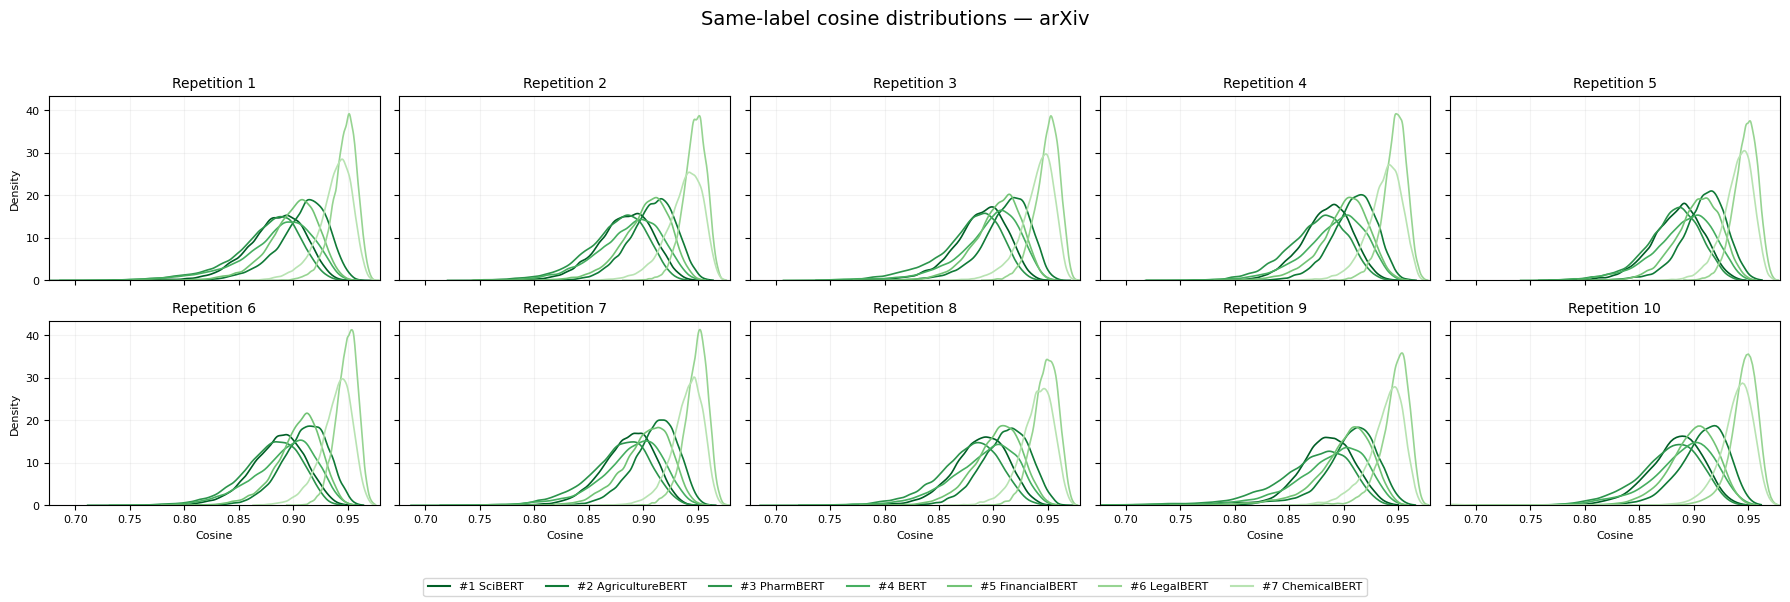

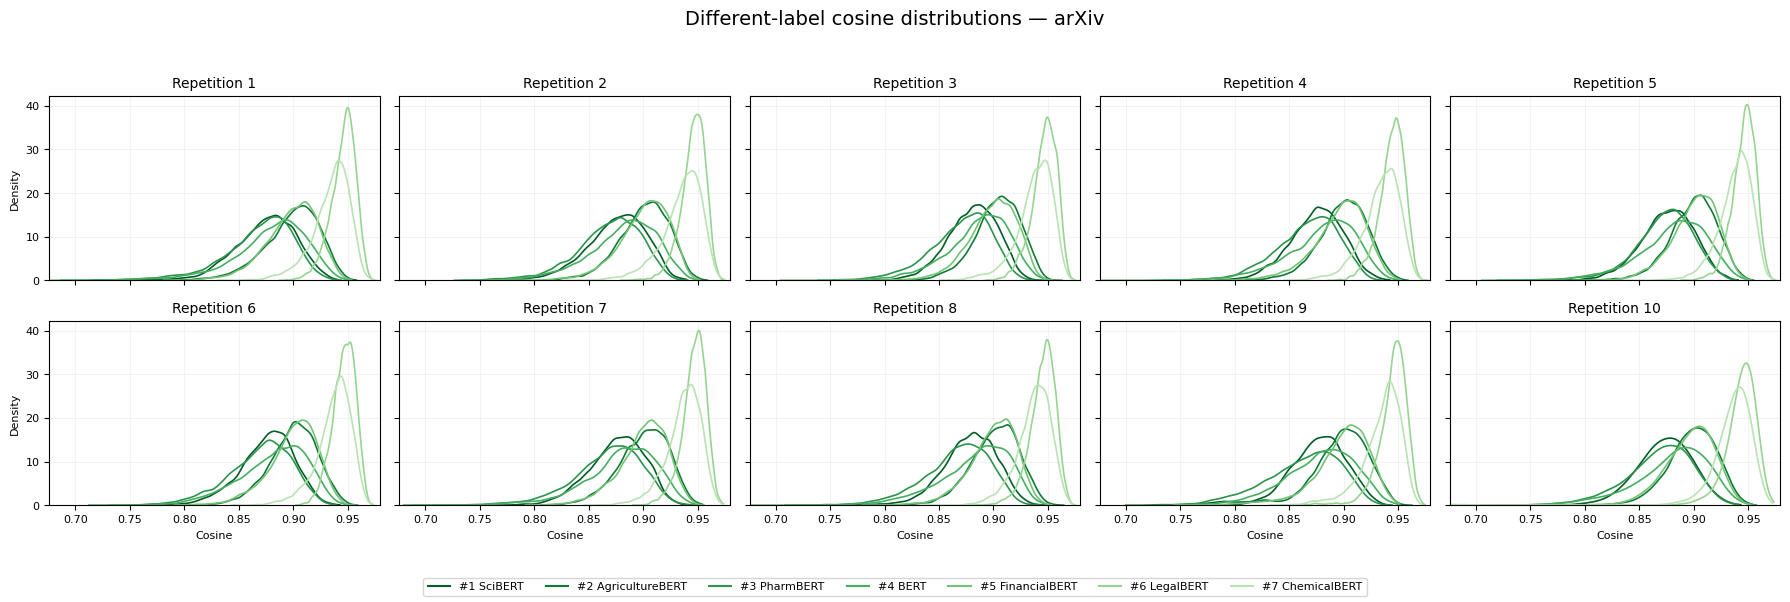

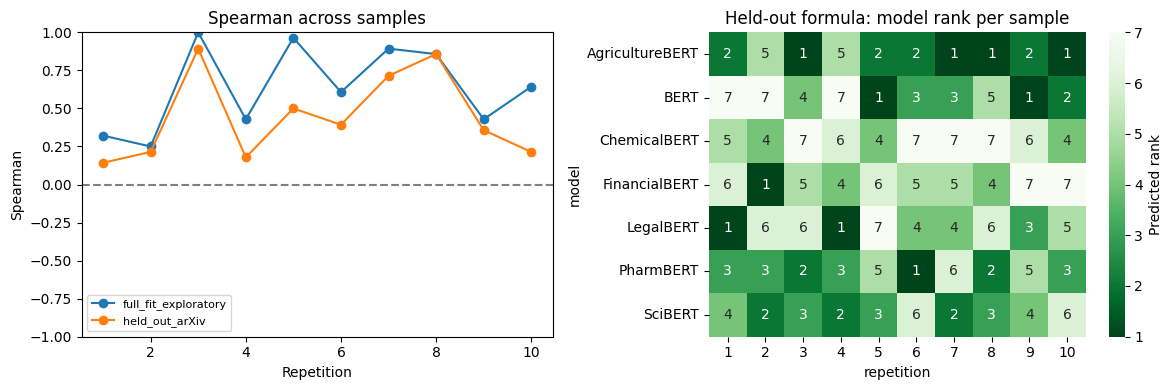

COMPLETED: 10 repetitions, 70 model runs. Results: /home/amyliu/Desktop/GR/arXiv/results/uncertainty10_gpu_20261025_185210


In [22]:
from matplotlib.lines import Line2D
name_to_checkpoint = {v:k for k,v in MODEL_NAMES.items()}
real_ranks = dict(zip(order, actual))
colors = {name:plt.cm.Greens(np.interp(real_ranks[name],[1,7],[.92,.30])) for name in order}
all_scores = np.concatenate([np.asarray(result[key],dtype=float)
    for result in results["full_results"].values() for key in ["same_scores","diff_scores_original"]])
xmin = max(-1, np.quantile(all_scores,.001)-.01)
xmax = min(1, np.quantile(all_scores,.999)+.01)
for key, title, filename in [
    ("same_scores","Same-label cosine distributions","same_label_all_10_repetitions.png"),
    ("diff_scores_original","Different-label cosine distributions","different_label_all_10_repetitions.png")]:
    fig, axes = plt.subplots(2,5,figsize=(18,6),sharex=True,sharey=True)
    for rep, ax in enumerate(axes.flat,start=1):
        for name in sorted(order,key=real_ranks.get):
            values = np.asarray(results["full_results"][(rep,name_to_checkpoint[name])][key],dtype=float)
            sns.kdeplot(x=values,ax=ax,color=colors[name],bw_adjust=.8,clip=(-1,1),cut=0,linewidth=1.2)
        ax.set_title(f"Repetition {rep}",fontsize=10)
        ax.set_xlim(xmin,xmax);ax.set_xlabel("Cosine",fontsize=8);ax.set_ylabel("Density",fontsize=8)
        ax.tick_params(labelsize=8);ax.grid(alpha=.15)
    fig.suptitle(title+" — arXiv",fontsize=14)
    fig.legend(handles=[Line2D([0],[0],color=colors[name],label=f"#{int(real_ranks[name])} {name}")
        for name in sorted(order,key=real_ranks.get)],loc="lower center",ncol=7,fontsize=8)
    fig.tight_layout(rect=[0,.07,1,.95])
    fig.savefig(OUTPUT_DIR / filename,dpi=180,bbox_inches="tight")
    plt.show();plt.close(fig)
fig, axes=plt.subplots(1,2,figsize=(12,4))
for procedure,g in round_df.groupby("procedure"):
    axes[0].plot(g.repetition,g.spearman,marker="o",label=procedure)
axes[0].axhline(0,color="gray",linestyle="--");axes[0].set_ylim(-1,1)
axes[0].set(xlabel="Repetition",ylabel="Spearman",title="Spearman across samples");axes[0].legend(fontsize=8)
rank_matrix=score_df.query('procedure == "held_out_arXiv"').pivot(index="model",columns="repetition",values="predicted_rank")
sns.heatmap(rank_matrix,annot=True,fmt=".0f",cmap="Greens_r",vmin=1,vmax=7,ax=axes[1],cbar_kws={"label":"Predicted rank"})
axes[1].set_title("Held-out formula: model rank per sample")
fig.tight_layout();fig.savefig(OUTPUT_DIR / "combination_stability.png",dpi=180,bbox_inches="tight")
plt.show();plt.close(fig)
print("COMPLETED: 10 repetitions, 70 model runs. Results:", OUTPUT_DIR.resolve())
